# Звіт про виконання практичного завдання №4 

## "Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень" 

### з дисципліни "Машинне навчання"

### Виконав:

### студент групи ФеІ-42

### Муртазін Максим

**Мета роботи:** Дослідити й порівняти три алгоритми класифікації — Decision Tree (DT), Random Forest (RF) та градієнтний бустинг XGBoost (XGB) — на реальному датасеті Annealing, що містить пропущені значення. Основна увага приділяється: впливу способу обробки пропусків на якість класифікації; коректному (без витоку даних) підбору гіперпараметрів за допомогою Optuna; неупередженому оцінюванню моделей (вкладена крос-валідація) та статистичному порівнянню результатів; інтерпретації моделей і розбіжностей між їхніми прогнозами (permutation importance, SHAP).

**Індивідуальний варіант.** N = 15, тому SEED = 42 + 15 = 57. Ця константа є єдиним джерелом випадковості: поділ даних, крос-валідація, моделі та семплер Optuna.

**Дані.** OpenML anneal, version=1: 898 спостережень, 38 ознак (6 числових і 32 категоріальні), цільова змінна — 5 класів (1, 2, 3, 5, U).

**Версії бібліотек** (повний перелік збережено у файлі requirements.txt): Python 3.12.8, scikit-learn 1.8.0, xgboost 3.2.0, optuna 5.0.0, shap 0.53.0, pandas 2.2.3, numpy 2.2.3, scipy 1.15.2, matplotlib 3.10.6, seaborn 0.13.2.

## Короткі теоретичні відомості

**Механізми виникнення пропусків.** *MCAR* — імовірність пропуску не залежить ні від спостережуваних, ні від неспостережуваних даних; *MAR* — залежить лише від спостережуваних ознак; *MNAR* — залежить від самого пропущеного значення або від неспостережуваних чинників. Якщо пропуски не є MCAR, сам факт пропуску може нести інформацію про цільову змінну, тому бінарні індикатори пропусків (варіант B) здатні покращити прогноз. У частини ознак пропуски *структурні*: ознака просто не застосовна до об'єкта, і її заповнення медіаною чи модою не має фізичного змісту.

**Оптимістичне зміщення.** Якщо гіперпараметри обрано за найкращим середнім значенням метрики на крос-валідації, то це значення — максимум серед багатьох зашумлених оцінок і тому завищує справжню якість. Неупереджену оцінку дає *вкладена крос-валідація*: зовнішній цикл оцінює якість, внутрішній підбирає гіперпараметри лише на тренувальній частині кожного зовнішнього блоку.

**Скоригований t-тест Надо–Бенжіо.** Блоки крос-валідації перетинаються за тренувальними даними, тому оцінки на різних блоках залежні, а звичайний парний t-тест занижує дисперсію. Для повторної $k$-блочної крос-валідації ($r$ повторень, обидві моделі оцінюються на однакових блоках) використовується

$$
t=\frac{\bar d}{\sqrt{\left(\dfrac{1}{kr}+\dfrac{n_{test}}{n_{train}}\right)\hat\sigma_d^{2}}},\qquad \text{ступені свободи: } kr-1,
$$

де $d_j$ — різниця метрик двох моделей на $j$-му блоці, $\bar d$ і $\hat\sigma_d^2$ — вибіркове середнє та дисперсія $d_j$.

## Налаштування середовища та індивідуальний варіант

In [1]:
import sys
import time
import subprocess
import warnings
import importlib.metadata as md
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
from IPython.display import display

import sklearn
import xgboost
import optuna
import shap

# Індивідуальний варіант
STUDENT_N = 15
SEED = 42 + STUDENT_N # джерело випадковості

# Константи експерименту
MODELS = ['DT', 'RF', 'XGB']
MODEL_TITLES = {'DT': 'Decision Tree', 'RF': 'Random Forest', 'XGB': 'XGBoost'}
N_TRIALS = 30 # кількість спроб Optuna на одне налаштування
N_PERM_REPEATS = 20 # повторення permutation importance
N_PERM_MC = 10_000 # перестановок у Монте-Карло критерії незалежності
ALPHA = 0.05 # рівень значущості

MODELS_DIR = Path('models')
MODELS_DIR.mkdir(exist_ok=True)

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')

# Версії бібліотек
print(f'SEED = 42 + {STUDENT_N} = {SEED}')
print(f'Python        : {sys.version.split()[0]}')
for pkg in ['scikit-learn', 'xgboost', 'optuna', 'shap', 'pandas', 'numpy', 'scipy',
            'matplotlib', 'seaborn']:
    print(f'{pkg:<13} : {md.version(pkg)}')

# requirements.txt
try:
    freeze = subprocess.run([sys.executable, '-m', 'pip', 'freeze'],
                            capture_output=True, text=True, check=True).stdout
except Exception:
    freeze = '\n'.join(f'{p}=={md.version(p)}' for p in
                       ['scikit-learn', 'xgboost', 'optuna', 'shap', 'pandas', 'numpy',
                        'scipy', 'matplotlib', 'seaborn', 'joblib'])
Path('requirements.txt').write_text(freeze)
print('requirements.txt збережено')

# Форматування масиву оцінок як 'середнє ± стандартне відхилення'
def fmt_ms(values):
    values = np.asarray(values, dtype=float)
    return f'{values.mean():.4f} ± {values.std(ddof=1):.4f}'

SEED = 42 + 15 = 57
Python        : 3.12.8
scikit-learn  : 1.8.0
xgboost       : 3.2.0
optuna        : 5.0.0
shap          : 0.53.0
pandas        : 2.2.3
numpy         : 2.2.3
scipy         : 1.15.2
matplotlib    : 3.10.6
seaborn       : 0.13.2
requirements.txt збережено


Задано SEED = 42 + 15 = 57; версії бібліотек виведено та збережено у requirements.txt. Усі версії не нижчі за мінімально потрібні (Python ≥ 3.10, scikit-learn ≥ 1.4, xgboost ≥ 2.0, optuna ≥ 3.0, shap ≥ 0.44). Фінальні моделі зберігаються в каталозі models/.

## 3.1 Первинний аналіз даних
**Кроки 1–2.** Завантаження датасету, визначення матриці ознак `X` і цільової змінної `y`, приведення категоріальних ознак до типу `object`, визначення кількості спостережень, ознак та їхніх типів.

In [2]:
from sklearn.datasets import fetch_openml

data = fetch_openml(name='anneal', version=1, as_frame=True)
X, y = data.data.copy(), data.target.copy()

# Категоріальні ознаки приводимо до типу object (пропуски лишаються NaN)
cat_cols_all = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
for c in cat_cols_all:
    X[c] = X[c].astype(object)
y = y.astype(str)

source = ('OpenML anneal v1 (898 спостережень)' if len(X) == 898
          else 'інша версія даних' + (' (UCI, 798)' if len(X) == 798 else ''))
print(f'Використано: {source}')
print(f'Спостережень: {X.shape[0]},  ознак: {X.shape[1]},  '
      f'числових: {X.shape[1] - len(cat_cols_all)},  категоріальних: {len(cat_cols_all)}')
display(X.dtypes.astype(str).rename('тип').to_frame())

Використано: OpenML anneal v1 (898 спостережень)
Спостережень: 898,  ознак: 38,  числових: 6,  категоріальних: 32


,тип
family,object
product-type,object
steel,object
carbon,int64
hardness,int64
temper_rolling,object
condition,object
formability,object
strength,int64
non-ageing,object


Використано версію OpenML (898 спостережень). Датасет містить 38 ознак: 6 числових (carbon, hardness, strength, thick, width, len) і 32 категоріальні, які приведено до типу `object`; пропуски при цьому лишаються значеннями `NaN`.

Повністю порожні ознаки (6): ['marvi', 's', 'p', 'corr', 'jurofm', 'm']
Константні ознаки      (7): ['product-type', 'm', 'marvi', 'corr', 'jurofm', 's', 'p']


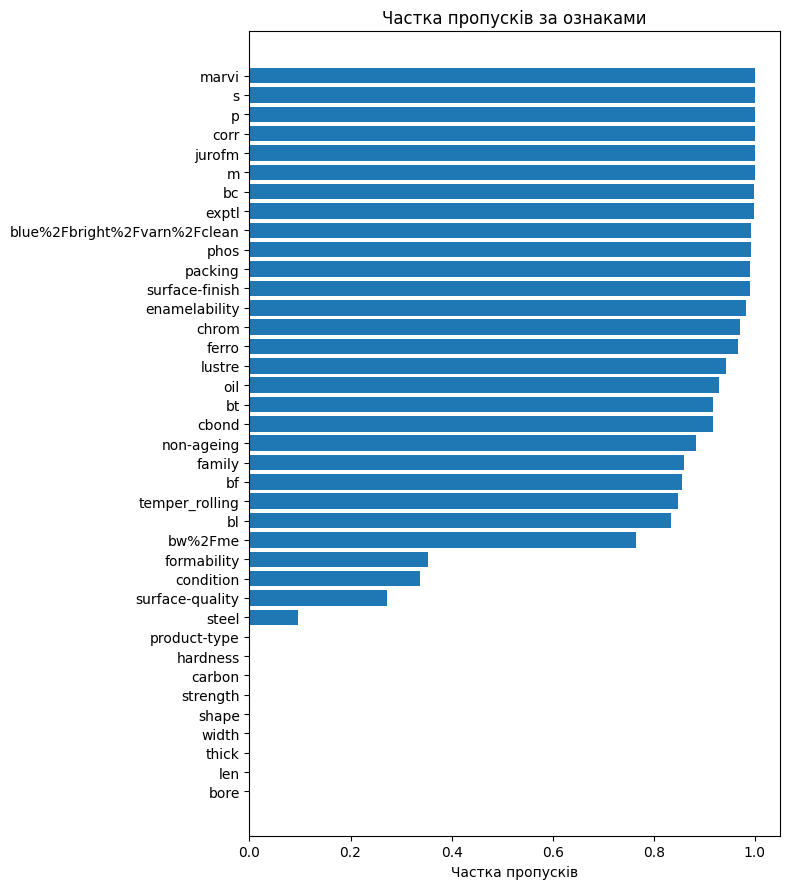

Після видалення: 31 ознак, з них з пропусками: 23


In [3]:
miss_frac_all = X.isna().mean().sort_values(ascending=False)

empty_cols = miss_frac_all[miss_frac_all == 1.0].index.tolist()               # 100 % NaN
const_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]        # одне значення
drop_cols = sorted(set(empty_cols) | set(const_cols))
print(f'Повністю порожні ознаки ({len(empty_cols)}): {empty_cols}')
print(f'Константні ознаки      ({len(const_cols)}): {const_cols}')

# Графік 2: частка пропусків за ознаками
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(miss_frac_all.index[::-1], miss_frac_all.values[::-1], color='tab:blue')
ax.set_xlabel('Частка пропусків')
ax.set_title('Частка пропусків за ознаками')
plt.tight_layout()
plt.show()

X = X.drop(columns=drop_cols)
miss_frac = X.isna().mean().sort_values(ascending=False)
print(f'Після видалення: {X.shape[1]} ознак, з них з пропусками: {(miss_frac > 0).sum()}')

Видалено 7 ознак: 6 повністю порожніх (`marvi`, `s`, `p`, `corr`, `jurofm`, `m`) і 1 константну (`product-type` — одне й те саме значення в усіх об'єктів). Обґрунтування: такі ознаки не несуть жодної інформації для розрізнення класів, а лише збільшують розмірність; повністю порожня ознака водночас є константною, тому в окремий перелік константних потрапила лише `product-type`. Залишилось 31 ознака, з яких 23 мають пропуски: у 19 з них пропущено понад 76 % значень, ще чотири мають помірну частку (formability 35.4 %, condition 33.7 %, surface-quality 27.2 %, steel 9.6 %). Усі 23 такі ознаки категоріальні, а 6 числових повні, тому на практиці імпутація зводиться до заповнення модою.

,кількість,частка
class,,
1,8,0.0089
2,99,0.1102
3,684,0.7617
5,67,0.0746
U,40,0.0445


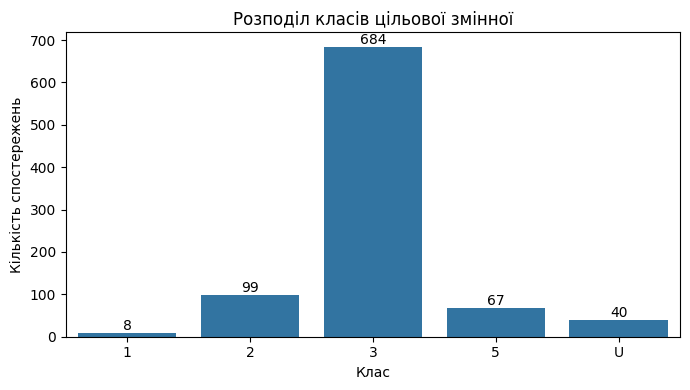

Найменший клас: 1 (8 спостережень)
Класи з < 5 спостережень: немає; політика: keep


In [4]:
class_counts = y.value_counts().sort_index()
display(pd.DataFrame({'кількість': class_counts,
                      'частка': (class_counts / class_counts.sum()).round(4)}))

# Графік 1: розподіл класів цільової змінної
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette=['tab:blue']*len(class_counts), legend=False, ax=ax)
for i, v in enumerate(class_counts.values):
    ax.text(i, v, str(v), ha='center', va='bottom')
ax.set_xlabel('Клас')
ax.set_ylabel('Кількість спостережень')
ax.set_title('Розподіл класів цільової змінної')
plt.tight_layout()
plt.show()

# Політика щодо рідких класів: 'keep' -- залишити, 'drop' -- виключити.
# Клас має мати >= 5 об'єктів, щоб після hold-out (80 %), зовнішнього (5 блоків)
# та внутрішнього (3 блоки) поділів він був у кожній тренувальній частині.
# Це явно перевіряється далі (check_class_coverage).
RARE_CLASS_POLICY = 'keep'
RARE_CLASS_THRESHOLD = 5

rare_classes = class_counts[class_counts < RARE_CLASS_THRESHOLD].index.tolist()
print(f'Найменший клас: {class_counts.idxmin()} ({class_counts.min()} спостережень)')
print(f'Класи з < {RARE_CLASS_THRESHOLD} спостережень: {rare_classes or "немає"}; '
      f'політика: {RARE_CLASS_POLICY}')
if RARE_CLASS_POLICY == 'drop' and rare_classes:
    keep_mask = ~y.isin(rare_classes)
    X, y = X.loc[keep_mask], y.loc[keep_mask]
    print(f'Виключено рідкісні класи {rare_classes}; залишилось {len(X)} спостережень')

Розподіл класів різко незбалансований: клас 3 — 684 об'єкти (76.2 %), клас 2 — 99 (11.0 %), клас 5 — 67 (7.5 %), клас U — 40 (4.5 %), клас 1 — лише 8 (0.9 %); клас 4 із документації в даних відсутній. Рішення: усі п'ять класів *залишено* (політика keep), бо навіть найменший клас має 8 об'єктів, що не менше порогу 5, а його виключення чи об'єднання з іншим класом прибрало б саме ту складність, яку досліджує робота. Вплив на крос-валідацію перевірено в п. 3.2: клас 1 є в кожній тренувальній частині, проте в одному валідаційному блоці його представлено 1–2 об'єктами, тому macro F1 на блоках буде дуже шумним.

In [5]:
# Статистика хі-квадрат Пірсона для таблиці спряженості
def pearson_chi2(tab):
    tab = np.asarray(tab, dtype=float)
    exp = np.outer(tab.sum(1), tab.sum(0)) / tab.sum()
    mask = exp > 0
    return (((tab - exp) ** 2)[mask] / exp[mask]).sum()

# Монте-Карло (перестановочний) тест незалежності пропуску й класу
def mc_chi2_test(miss, y_codes, n_classes, n_perm, rng):
    def table(yy):
        return np.bincount(miss.astype(int) * n_classes + yy,
                           minlength=2 * n_classes).reshape(2, n_classes)
    obs = pearson_chi2(table(y_codes))
    perm = np.array([pearson_chi2(table(rng.permutation(y_codes))) for _ in range(n_perm)])
    return obs, (1 + np.sum(perm >= obs - 1e-9)) / (n_perm + 1)


N_TOP_MISSING = 35
top_missing = miss_frac[miss_frac > 0].head(N_TOP_MISSING).index.tolist()
y_codes_mech, y_labels_mech = pd.factorize(y)
rng_mech = np.random.default_rng(SEED)

contingency = {}
rows = []
for f in top_missing:
    m = X[f].isna().to_numpy()
    ct = pd.crosstab(pd.Series(np.where(m, 'пропуск', 'є значення'), index=X.index, name='ознака'),
                     y.rename('клас'))
    contingency[f] = ct
    chi2, p_chi, dof, expected = stats.chi2_contingency(ct.values, correction=False)
    if expected.min() >= 5:
        test_name, stat, p_val = 'χ²', chi2, p_chi
    else:
        test_name = 'Монте-Карло χ²'
        stat, p_val = mc_chi2_test(m, y_codes_mech, len(y_labels_mech), N_PERM_MC, rng_mech)
    rows.append({'ознака': f, 'частка пропусків': m.mean(), 'тест': test_name,
                 'статистика': stat, 'p': p_val, 'залежить від класу': p_val < ALPHA})

mech = pd.DataFrame(rows).set_index('ознака')
display(mech.round(4))
print(f'Ознак, де пропуск залежить від класу (p < {ALPHA}): '
      f'{int(mech["залежить від класу"].sum())} із {len(mech)}')

print('Таблиці спряженості (3 ознаки з найбільшою часткою пропусків):')
for f in top_missing[:3]:
    print(f'\n{f}:')
    display(contingency[f])

,частка пропусків,тест,статистика,p,залежить від класу
ознака,,,,,
bc,0.9989,Монте-Карло χ²,0.3132,1.0000,False
exptl,0.9978,Монте-Карло χ²,222.9967,0.0002,True
blue%2Fbright%2Fvarn%2Fclean,0.9933,Монте-Карло χ²,37.3654,0.0008,True
phos,0.9922,Монте-Карло χ²,87.5030,0.0001,True
packing,0.9900,Монте-Карло χ²,2.8443,0.4452,False
surface-finish,0.9900,Монте-Карло χ²,73.3717,0.0001,True
enamelability,0.9822,Монте-Карло χ²,44.4376,0.0004,True
chrom,0.9710,Монте-Карло χ²,332.0928,0.0001,True
ferro,0.9666,Монте-Карло χ²,384.9498,0.0001,True


Ознак, де пропуск залежить від класу (p < 0.05): 21 із 23
Таблиці спряженості (3 ознаки з найбільшою часткою пропусків):

bc:


клас,1,2,3,5,U
ознака,,,,,
пропуск,8,99,683,67,40
є значення,0,0,1,0,0



exptl:


клас,1,2,3,5,U
ознака,,,,,
пропуск,6,99,684,67,40
є значення,2,0,0,0,0



blue%2Fbright%2Fvarn%2Fclean:


клас,1,2,3,5,U
ознака,,,,,
пропуск,7,95,683,67,40
є значення,1,4,1,0,0


Пропуски є лише у 23 ознак, тому перевірено всі 23, а не 35). В усіх таблицях спряженості очікувані частоти менші за 5, тому скрізь застосовано Монте-Карло варіант χ²-критерію (10 000 перестановок міток класу; це аналог точного критерію, мінімально можливе p ≈ 0.0001). Для 21 із 23 ознак гіпотезу про незалежність пропуску та класу відхилено (p < 0.05, без поправки на множинні порівняння); навіть за поправкою Бонферроні (0.05/23 ≈ 0.0022) значущими лишаються 18 ознак. Незалежність не відхилено лише для bc (p = 1.0; єдине непропущене значення належить класу 3) і packing (p = 0.4452), але вони майже порожні (99.9 % і 99.0 %), тож тест для них має мізерну потужність. Найсильніший зв'язок із класом мають surface-quality (χ² = 495.6), family (463.7), ferro (385.0) та chrom (332.1); показово, що значення exptl є лише у двох об'єктів класу 1.

Висновок: пропуски *не схожі на MCAR* — вони пов'язані з класом. Гіпотеза про механізм: це MAR (імовірність пропуску залежить від спостережуваних величин — класу та типу продукції) зі значною структурною складовою (ознака не застосовна до певного типу сталі); для частини ознак не можна виключити й MNAR, який за самими даними від MAR однозначно не відрізнити. Отже, індикатори пропусків мають бути корисними.

## 3.2 Кодування цілі, поділ даних і схеми крос-валідації
Кодування цілі через LabelEncoder (числа 0, …, K−1, цього вимагає XGBoost), стратифікований поділ 80/20, налаштування схем крос-валідації (єдиний об'єкт `cv` для всіх моделей і варіантів та зовнішня схема outer для вкладеної CV) і перевірка мінімальної кількості об'єктів кожного класу на кожному рівні.

In [6]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     StratifiedKFold)

le = LabelEncoder()
y_enc = le.fit_transform(y)
class_names = le.classes_.astype(str)
K = len(class_names)
print(f'Класи ({K}): {dict(enumerate(class_names.tolist()))}')

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED
)
print(f'Train: {X_train.shape},  Test: {X_test.shape}')

# Схеми крос-валідації. Об'єкт cv єдиний для всіх моделей і варіантів, тому блоки однакові й можливе парне порівняння
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # зовнішня


# Перевіряє, що в кожній тренувальній частині на всіх рівнях CV є всі класи
def check_class_coverage(y_arr, n_classes):
    Xd = np.zeros((len(y_arr), 1))
    report = []

    def _check(level, splits):
        min_tr, min_va = np.inf, np.inf
        for tr, va in splits:
            min_tr = min(min_tr, np.bincount(y_arr[tr], minlength=n_classes).min())
            min_va = min(min_va, np.bincount(y_arr[va], minlength=n_classes).min())
        report.append({'рівень': level, 'мін. об\'єктів класу у train-частині': int(min_tr),
                       'мін. об\'єктів класу у val-частині': int(min_va)})

    full = np.arange(len(y_arr))
    _check('уся тренувальна вибірка', [(full, full)])
    _check('повторна CV 5x3 (п. 3.3)', cv.split(Xd, y_arr))
    _check('зовнішня CV, 5 блоків (п. 3.4)', outer.split(Xd, y_arr))
    inner_splits = []
    for tr_o, _ in outer.split(Xd, y_arr):
        inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
        inner_splits += [(tr_o[a], tr_o[b]) for a, b in inner_cv.split(Xd[tr_o], y_arr[tr_o])]
    _check('внутрішня CV, 3 блоки (у кожному зовнішньому блоці)', inner_splits)
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    _check('внутрішня CV на всій тренувальній вибірці (фінальна оптимізація)',
           inner_cv.split(Xd, y_arr))
    return pd.DataFrame(report).set_index('рівень')


coverage = check_class_coverage(y_train, K)
display(coverage)
assert (coverage.iloc[:, 0] >= 1).all(), 'У якійсь тренувальній частині немає одного з класів!'

Класи (5): {0: '1', 1: '2', 2: '3', 3: '5', 4: 'U'}
Train: (718, 31),  Test: (180, 31)


,мін. об'єктів класу у train-частині,мін. об'єктів класу у val-частині
рівень,,
уся тренувальна вибірка,6,6
повторна CV 5x3 (п. 3.3),4,1
"зовнішня CV, 5 блоків (п. 3.4)",4,1
"внутрішня CV, 3 блоки (у кожному зовнішньому блоці)",2,1
внутрішня CV на всій тренувальній вибірці (фінальна оптимізація),4,2


LabelEncoder кодує класи 1, 2, 3, 5, U числами 0–4 (K = 5). Стратифікований поділ дав 718 об'єктів для навчання й 180 для тесту; тестова вибірка використовується лише в п. 3.6–3.8. Таблиця перевірки показує мінімальну кількість об'єктів будь-якого класу в тренувальній і валідаційній частинах кожного рівня: найменший клас (1) має 6 об'єктів у train, 4 — у тренувальних частинах повторної та зовнішньої CV і щонайменше 2 — у тренувальних частинах внутрішньої 3-блочної CV (у валідаційних частинах — 1 об'єкт). Отже, усі класи присутні в кожній тренувальній частині (XGBoost не завершиться помилкою), а кількість об'єктів найменшого класу не менша за кількість блоків зовнішньої CV (6 ≥ 5); саме тому внутрішня CV має 3 блоки. Водночас один об'єкт класу 1 у валідаційному блоці означає, що macro F1 на блоках має велику дисперсію.

## 3.2 Пайплайни обробки пропусків та 3.3 фабрика моделей
Побудовано два варіанти обробки: **A** — базова імпутація (числові — медіана, категоріальні — мода, one-hot кодування); **B** — як A, плюс бінарні індикатори пропусків для ознак, що мали пропуски в тренувальних даних.

In [7]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'),
         make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore',
                                     sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        # error_on_new=False: ознака з пропусками лише у валідаційному блоці не повинна обривати крос-валідацію
        transformers.append(
            ('miss', MissingIndicator(features='missing-only', error_on_new=False),
             make_column_selector()))
    return ColumnTransformer(transformers)


def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    return XGBClassifier(random_state=SEED, n_jobs=-1,
                         eval_metric='mlogloss', **params)


def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([('prep', build_preprocessor(with_indicators)),
                     ('clf', make_model(name, params))])

Уся обробка виконується всередині Pipeline/ColumnTransformer, тому імпутер і кодувальник навчаються лише на тренувальній частині кожного блоку крос-валідації — витоку даних немає. Імпутацію застосовано явно, щоб усі моделі отримували однакові вхідні дані й порівняння було контрольованим. Параметр `error_on_new=False` у `MissingIndicator` лише запобігає аварійній зупинці, коли ознака має пропуски тільки у валідаційному блоці. Для ознак із часткою пропусків понад 90 % імпутація модою створює майже константні стовпці, тож їхня інформація у варіанті A фактично втрачається, а у варіанті B зберігається в індикаторі.

## 3.3 Базові моделі
Три моделі з типовими гіперпараметрами для кожного варіанта обробки оцінено повторною стратифікованою крос-валідацією (5 блоків × 3 повторення) на тренувальній вибірці за accuracy, macro F1 (основна) і balanced accuracy. Усі моделі й варіанти оцінюються на одному й тому самому об'єкті `cv`, тобто на однакових блоках.

In [8]:
from sklearn.model_selection import cross_validate

scoring = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}

cv_results = {}
for variant, with_ind in [('A', False), ('B', True)]:
    for name in MODELS:
        cv_results[(variant, name)] = cross_validate(
            build_pipeline(name, with_indicators=with_ind), X_train, y_train,
            cv=cv, scoring=scoring, error_score='raise'
        )


def cv_table(variant):
    rows = []
    for name in MODELS:
        r = cv_results[(variant, name)]
        rows.append({'Модель': MODEL_TITLES[name],
                     'Accuracy': fmt_ms(r['test_acc']),
                     'Macro F1': fmt_ms(r['test_f1m']),
                     'Balanced acc.': fmt_ms(r['test_bacc'])})
    return pd.DataFrame(rows).set_index('Модель')


print('Таблиця 1. Варіант A (імпутація без індикаторів), типові гіперпараметри')
display(cv_table('A'))
print('Таблиця 2. Варіант B (імпутація + індикатори пропусків), типові гіперпараметри')
display(cv_table('B'))

Таблиця 1. Варіант A (імпутація без індикаторів), типові гіперпараметри


,Accuracy,Macro F1,Balanced acc.
Модель,,,
Decision Tree,0.9447 ± 0.0195,0.8486 ± 0.0934,0.8673 ± 0.1011
Random Forest,0.9494 ± 0.0177,0.8734 ± 0.1058,0.8780 ± 0.1007
XGBoost,0.9527 ± 0.0124,0.8341 ± 0.0968,0.8309 ± 0.0969


Таблиця 2. Варіант B (імпутація + індикатори пропусків), типові гіперпараметри


,Accuracy,Macro F1,Balanced acc.
Модель,,,
Decision Tree,0.9930 ± 0.0053,0.9142 ± 0.0927,0.9176 ± 0.0924
Random Forest,0.9958 ± 0.0058,0.9271 ± 0.0959,0.9263 ± 0.0961
XGBoost,0.9907 ± 0.0090,0.9179 ± 0.0942,0.9228 ± 0.0960


Результати подано як середнє ± стандартне відхилення за 15 блоками. Додавання індикаторів пропусків різко підвищує якість: accuracy зростає з 0.9447–0.9527 (варіант A) до 0.9907–0.9958 (варіант B), а macro F1 — з 0.8341–0.8734 до 0.9142–0.9271. За macro F1 у варіанті B найкращою є Random Forest (0.9271), далі XGBoost (0.9179) і Decision Tree (0.9142); у варіанті A порядок інший (RF, DT, XGBoost), тобто без індикаторів XGBoost виявився гіршим за одне дерево. Стандартне відхилення macro F1 (≈0.09–0.11) значно більше за стандартне відхилення accuracy (0.005–0.02): воно визначається рідкісними класами (в одному валідаційному блоці всього 1–2 об'єкти класу 1), тож різниці між моделями в межах 0.01–0.02 можуть бути шумом — це перевіряється в п. 3.5.

## 3.4 Підбір гіперпараметрів за допомогою Optuna та вкладена крос-валідація
Оптимізація виконується для варіанта B. У цільову функцію передається весь пайплайн (обробка + модель), а не заздалегідь оброблені дані, інакше імпутер бачить валідаційні блоки й виникає витік.

In [9]:
from sklearn.model_selection import cross_val_score


def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical(
                'class_weight', [None, 'balanced']),
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical(
                'max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical(
                'class_weight', [None, 'balanced', 'balanced_subsample']),
        }
    return {  # XGB
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
    }


def tune(name, X_tr, y_tr, n_trials=30):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner,
                               scoring='f1_macro', error_score='raise').mean()

    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

Функція `tune()` оптимізує macro F1 за 3-блочною стратифікованою крос-валідацією (`StratifiedKFold`, `random_state=SEED`) з семплером TPE і 30 спробами. Оскільки в `cross_val_score` потрапляє весь пайплайн, імпутація та індикатори навчаються лише на внутрішніх тренувальних блоках. Простір пошуку: для DT — глибина, `min_samples_split`, `min_samples_leaf`, `class_weight`; для RF — кількість дерев, глибина, `min_samples_leaf`, `max_features`, `class_weight`; для XGBoost — кількість дерев, глибина, `learning_rate`, `subsample`, `colsample_bytree`, `min_child_weight`.

In [10]:
from sklearn.metrics import f1_score

nested_scores = {n: [] for n in MODELS}

for name in MODELS:
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        study = tune(name, X_tr, y_tr, N_TRIALS)
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)
        nested_scores[name].append(f1_score(y_va, model.predict(X_va), average='macro'))

Для кожної моделі виконано зовнішню 5-блочну стратифіковану крос-валідацію: на кожному зовнішньому блоці `tune()` запускався лише на його тренувальній частині, модель навчалася з найкращими знайденими параметрами, а macro F1 обчислювався на відкладеному зовнішньому блоці. Таким чином оцінюється якість усієї процедури «підбір гіперпараметрів + навчання»; результати подано в таблиці 3.

In [11]:
studies, final_models = {}, {}

for name in MODELS:
    studies[name] = tune(name, X_train, y_train, N_TRIALS)
    final_models[name] = build_pipeline(name, True, studies[name].best_params).fit(X_train, y_train)
    joblib.dump(final_models[name], MODELS_DIR / f'final_{name}.joblib')

# Таблиця 3: вкладена CV vs best_value однієї звичайної оптимізації
rows = []
for name in MODELS:
    rows.append({'Модель': MODEL_TITLES[name],
                 'Macro F1 (вкладена CV)': fmt_ms(nested_scores[name]),
                 'best_value (1 оптимізація на всьому train)': round(studies[name].best_value, 4),
                 'best_value - вкладена CV': round(studies[name].best_value
                                                   - np.mean(nested_scores[name]), 4)})
print('Таблиця 3. Вкладена CV (варіант B, після оптимізації) та best_value')
display(pd.DataFrame(rows).set_index('Модель'))

# Таблиця 4: найкращі гіперпараметри
table4 = pd.DataFrame({MODEL_TITLES[n]: pd.Series(studies[n].best_params, dtype=object)
                       for n in MODELS}).fillna('—')
print('Таблиця 4. Найкращі гіперпараметри (Optuna, весь train)')
display(table4)

Таблиця 3. Вкладена CV (варіант B, після оптимізації) та best_value


,Macro F1 (вкладена CV),best_value (1 оптимізація на всьому train),best_value - вкладена CV
Модель,,,
Decision Tree,0.8470 ± 0.0644,0.9479,0.1009
Random Forest,0.9406 ± 0.0859,0.9524,0.0119
XGBoost,0.8950 ± 0.1027,0.9287,0.0337


Таблиця 4. Найкращі гіперпараметри (Optuna, весь train)


,Decision Tree,Random Forest,XGBoost
class_weight,—,—,—
colsample_bytree,—,—,0.718574
learning_rate,—,—,0.015684
max_depth,18,25,7
max_features,—,sqrt,—
min_child_weight,—,—,1.390636
min_samples_leaf,1,1,—
min_samples_split,3,—,—
n_estimators,—,400,287
subsample,—,—,0.887011


**Коментар до таблиці 3.** `best_value` завищує якість порівняно з вкладеною крос-валідацією в усіх трьох моделей: DT — 0.9479 проти 0.8470 ± 0.0644 (різниця 0.1009), RF — 0.9524 проти 0.9406 ± 0.0859 (0.0119), XGBoost — 0.9287 проти 0.8950 ± 0.1027 (0.0337). Причина — оптимістичне зміщення: `best_value` є максимумом серед 30 зашумлених оцінок на тих самих блоках, тож обрана конфігурація частково підлаштована під шум цих блоків, тоді як вкладена CV оцінює її на даних, що не брали участі в підборі. Зміщення найбільше для DT, бо окреме дерево нестабільне і якість різних конфігурацій коливається в широких межах, а в RF багато конфігурацій дають близькі значення (плато біля 0.95), тому відбір майже не завищує оцінку. Вкладена оцінка DT (0.8470) нижча за оцінку базового дерева у варіанті B (0.9142), але ці оцінки отримано на різних розбиттях і вони мають розкид ≈0.06–0.09, тож це не доводить, що оптимізація погіршила модель; знайдена конфігурація близька до типової (`min_samples_leaf = 1`, глибина 18).

**Коментар до таблиці 4.** Найкращі гіперпараметри: DT — `max_depth = 18`, `min_samples_split = 3`, `min_samples_leaf = 1`; RF — `n_estimators = 400`, `max_depth = 25`, `min_samples_leaf = 1`, `max_features = 'sqrt'`; XGBoost — `n_estimators = 287`, `max_depth = 7`, `learning_rate ≈ 0.0157`, `subsample ≈ 0.887`, `colsample_bytree ≈ 0.719`, `min_child_weight ≈ 1.39`. Прочерк означає, що параметр для моделі не підбирався; виняток — `class_weight` для DT і RF, де «—» відповідає значенню `None` (ваги класів не потрібні). І DT, і RF обрали мінімально можливий розмір листка (`min_samples_leaf = 1`), а XGBoost — малу швидкість навчання з великою кількістю дерев.

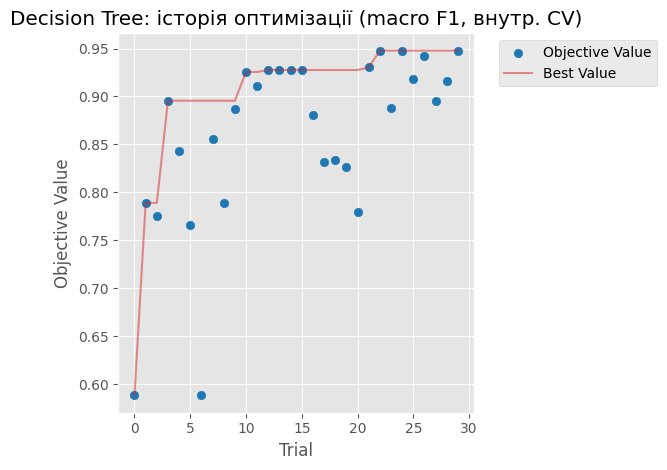

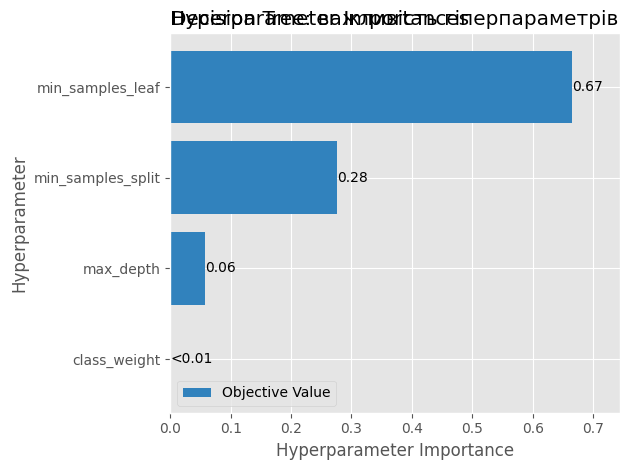

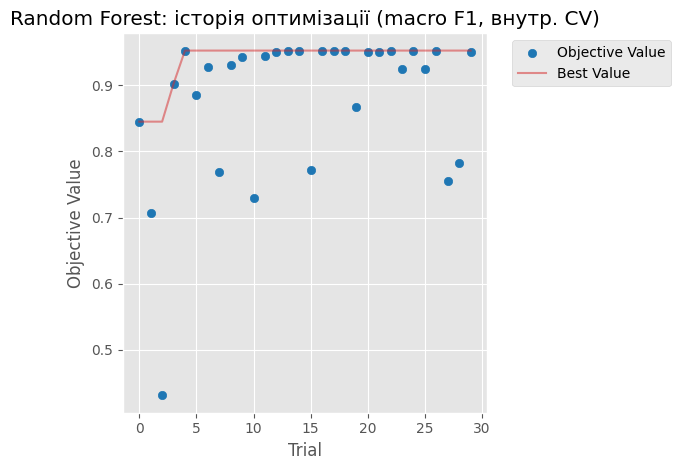

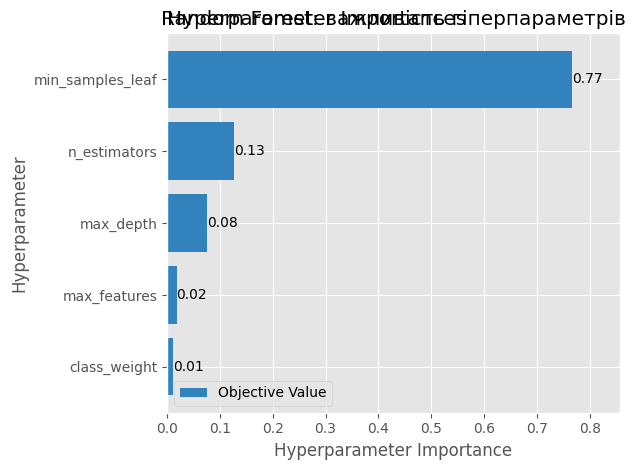

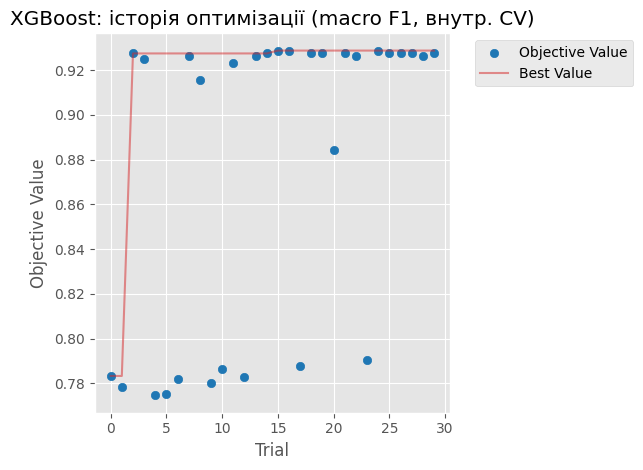

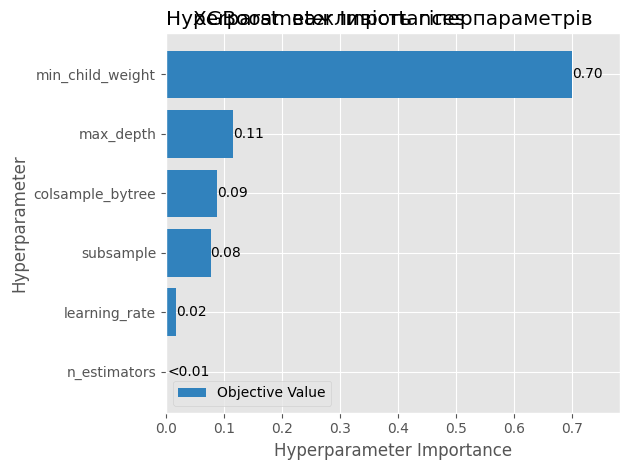

In [12]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

for name in MODELS:
    ax = plot_optimization_history(studies[name])
    ax.set_title(f'{MODEL_TITLES[name]}: історія оптимізації (macro F1, внутр. CV)')
    ax.figure.tight_layout()
    plt.show()

    ax = plot_param_importances(studies[name])
    ax.set_title(f'{MODEL_TITLES[name]}: важливість гіперпараметрів')
    ax.figure.tight_layout()
    plt.show()

*Decision Tree:* найкраще значення швидко зростає за перші 10 спроб (від 0.59 до ≈0.925), ще раз стрибає на 22-й спробі (до 0.9479) і далі до 30-ї не змінюється; розкид значень великий (0.59–0.95), тож за 30 спроб оптимізація збіглася лише приблизно. Найважливіші параметри — `min_samples_leaf` (0.67) і `min_samples_split` (0.28), `max_depth` — 0.06, `class_weight` — менше 0.01.

*Random Forest:* значення ≈0.952 досягнуто вже на 5-й спробі, після чого більшість спроб лежить на плато біля 0.95 (поодинокі провали до 0.43–0.78) — оптимізація збіглася. Найважливіший параметр — `min_samples_leaf` (0.77), далі `n_estimators` (0.13) і `max_depth` (0.08); `max_features` та `class_weight` майже не впливають (0.02 і 0.01).

*XGBoost:* ≈0.927 досягнуто на 3-й спробі, далі лише мікроприріст до 0.9287 — оптимізація збіглася, проте частина спроб (≈0.77–0.79) помітно гірша. Найважливіший параметр — `min_child_weight` (0.70), далі `max_depth` (0.11), `colsample_bytree` (0.09) і `subsample` (0.08); `learning_rate` (0.02) та `n_estimators` (менше 0.01) практично не впливають.

Спільна риса: домінують параметри, що задають мінімальний розмір листка чи вузла. Імовірно, великі значення таких параметрів не дозволяють виділити рідкісні класи (1 та U), що знижує macro F1. Оскільки спроб лише 30, ці оцінки важливості орієнтовні.

## 3.5 Статистичне порівняння
На основі результатів п. 3.3 скоригованим t-тестом Надо–Бенжіо при α = 0.05 перевірено: 1) чи значуща різниця macro F1 між варіантами A і B для кожної моделі; 2) чи значуща різниця між двома найкращими моделями у варіанті B.

In [13]:
# Скоригований t-тест Надо-Бенжіо для різниць d на kr блоках повторної CV
def nadeau_bengio(d, n_test_over_n_train):
    d = np.asarray(d, dtype=float)
    kr, d_mean, var = d.size, d.mean(), d.var(ddof=1)
    if var == 0:                                    # усі різниці однакові
        t = 0.0 if d_mean == 0 else np.sign(d_mean) * np.inf
    else:
        t = d_mean / np.sqrt((1 / kr + n_test_over_n_train) * var)
    p = 2 * stats.t.sf(abs(t), df=kr - 1)
    return d_mean, t, p


# відношення n_test / n_train у блоках cv
cv_splits = list(cv.split(X_train, y_train))
ratio = (np.mean([len(te) for _, te in cv_splits]) /
         np.mean([len(tr) for tr, _ in cv_splits]))

f1_cv = {k: v['test_f1m'] for k, v in cv_results.items()}   # однакові блоки для всіх
rows = []

# 1) Варіант A vs B для кожної моделі
for name in MODELS:
    d_mean, t, p = nadeau_bengio(f1_cv[('B', name)] - f1_cv[('A', name)], ratio)
    rows.append({'Порівняння': f'{MODEL_TITLES[name]}: B - A (macro F1)',
                 'd̄': d_mean, 't': t, 'p': p,
                 'Висновок': ('значуща відмінність' if p < ALPHA else 'відмінність незначуща')
                             + f' (α = {ALPHA})'})

# 2) Дві найкращі моделі у варіанті B за середнім macro F1
ranking_B = sorted(MODELS, key=lambda n: f1_cv[('B', n)].mean(), reverse=True)
m1, m2 = ranking_B[:2]
d_mean, t, p = nadeau_bengio(f1_cv[('B', m1)] - f1_cv[('B', m2)], ratio)
rows.append({'Порівняння': f'{MODEL_TITLES[m1]} - {MODEL_TITLES[m2]} (варіант B, macro F1)',
             'd̄': d_mean, 't': t, 'p': p,
             'Висновок': ('значуща відмінність' if p < ALPHA else 'відмінність незначуща')
                         + f' (α = {ALPHA})'})

print('Таблиця 5. Скоригований t-тест Надо-Бенжіо')
display(pd.DataFrame(rows).set_index('Порівняння').round(4))

Таблиця 5. Скоригований t-тест Надо-Бенжіо


,d̄,t,p,Висновок
Порівняння,,,,
Decision Tree: B - A (macro F1),0.0656,4.5746,0.0004,значуща відмінність (α = 0.05)
Random Forest: B - A (macro F1),0.0537,4.9476,0.0002,значуща відмінність (α = 0.05)
XGBoost: B - A (macro F1),0.0839,1.6478,0.1217,відмінність незначуща (α = 0.05)
"Random Forest - XGBoost (варіант B, macro F1)",0.0091,0.8572,0.4058,відмінність незначуща (α = 0.05)


Тест виконано для 15 блоків (df = 14, $n_{test}/n_{train} \approx 0.25$); $d$ — різниця macro F1 на кожному блоці. **1) Варіанти B і A.** Індикатори пропусків значуще покращили DT ($\bar d = 0.0656$, t = 4.5746, p = 0.0004) і RF ($\bar d = 0.0537$, t = 4.9476, p = 0.0002). Для XGBoost середня різниця найбільша (0.0839), але незначуща (t = 1.6478, p = 0.1217): стандартна похибка різниці для XGBoost (≈0.051) у 3.5–4.7 раза більша, ніж для DT (≈0.014) і RF (≈0.011), тобто різниця по блоках дуже нестабільна, і висновок лише за середнім був би хибним. **2) Дві найкращі моделі у варіанті B** — Random Forest і XGBoost: $\bar d = 0.0091$, t = 0.8572, p = 0.4058, відмінність незначуща, перевага RF лежить у межах шуму. Поправка Бонферроні на 4 тести (поріг 0.0125) цих висновків не змінює. Відсутність значущої різниці — це результат, який слід інтерпретувати, а не помилка.

## 3.6 Фінальна оцінка на тестовій вибірці
Для фінальних моделей (варіант B, після оптимізації) обчислено accuracy, macro F1 і balanced accuracy на тесті, `classification_report` і матриці плутанини для найкращої моделі. Найкращу модель обрано за вкладеною крос-валідацією — це Random Forest.

Таблиця 6. Фінальні моделі (варіант B) на тестовій вибірці


,Accuracy,Macro F1,Balanced acc.
Модель,,,
Decision Tree,0.9778,0.9471,0.9471
Random Forest,0.9778,0.9471,0.9471
XGBoost,0.9722,0.8797,0.8471



classification_report -- Random Forest (найкраща за вкладеною CV):
              precision    recall  f1-score   support

           1      1.000     1.000     1.000         2
           2      1.000     1.000     1.000        20
           3      0.985     0.985     0.985       137
           5      1.000     1.000     1.000        13
           U      0.750     0.750     0.750         8

    accuracy                          0.978       180
   macro avg      0.947     0.947     0.947       180
weighted avg      0.978     0.978     0.978       180



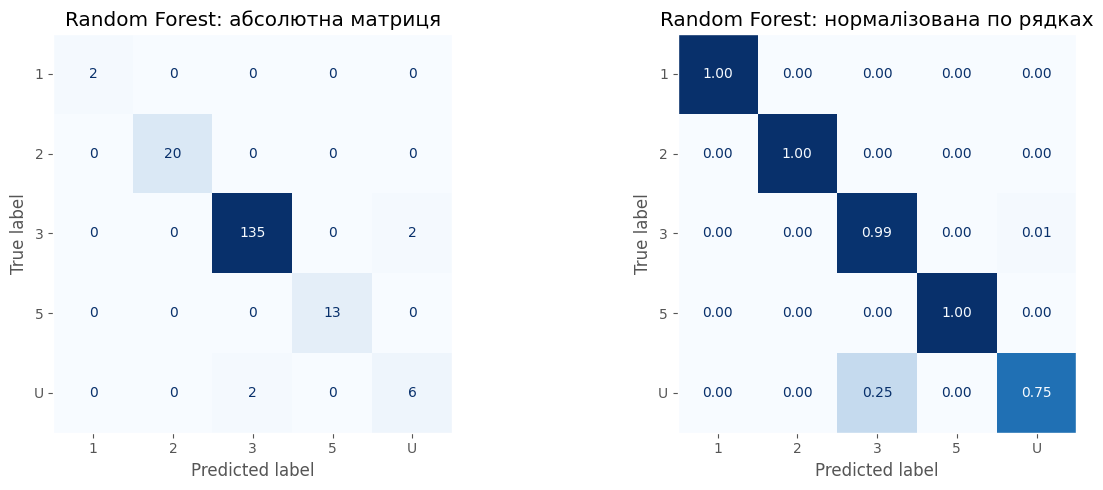

Найчастіші помилки (справжній клас -> прогноз):


,справжній клас,прогноз,кількість
0,3,U,2
1,U,3,2


In [14]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

test_pred = {n: final_models[n].predict(X_test) for n in MODELS}

rows = []
for n in MODELS:
    rows.append({'Модель': MODEL_TITLES[n],
                 'Accuracy': accuracy_score(y_test, test_pred[n]),
                 'Macro F1': f1_score(y_test, test_pred[n], average='macro'),
                 'Balanced acc.': balanced_accuracy_score(y_test, test_pred[n])})
print('Таблиця 6. Фінальні моделі (варіант B) на тестовій вибірці')
display(pd.DataFrame(rows).set_index('Модель').round(4))

# Найкраща модель обирається за вкладеною CV
best_name = max(MODELS, key=lambda n: np.mean(nested_scores[n]))
print(f'\nclassification_report -- {MODEL_TITLES[best_name]} (найкраща за вкладеною CV):')
print(classification_report(y_test, test_pred[best_name], labels=np.arange(K),
                            target_names=class_names, digits=3, zero_division=0))

# Графік 5: абсолютна та нормалізована (по рядках) матриці плутанини
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred[best_name], labels=np.arange(K), display_labels=class_names,
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'{MODEL_TITLES[best_name]}: абсолютна матриця')
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred[best_name], labels=np.arange(K), display_labels=class_names,
    normalize='true', values_format='.2f', ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title(f'{MODEL_TITLES[best_name]}: нормалізована по рядках')
for a in axes:
    a.grid(False)
plt.tight_layout()
plt.show()

# Які класи найчастіше плутаються між собою
cm = confusion_matrix(y_test, test_pred[best_name], labels=np.arange(K))
np.fill_diagonal(cm, 0)
pairs = sorted([(class_names[i], class_names[j], int(cm[i, j]))
                for i in range(K) for j in range(K) if cm[i, j] > 0], key=lambda r: -r[2])
print('Найчастіші помилки (справжній клас -> прогноз):')
display(pd.DataFrame(pairs, columns=['справжній клас', 'прогноз', 'кількість'])
        if pairs else pd.DataFrame({'повідомлення': ['помилок на тесті немає']}))

**Коментар (таблиця і графік).** На тесті DT і RF мають однакові метрики (accuracy 0.9778, macro F1 0.9471, balanced accuracy 0.9471), XGBoost — 0.9722, 0.8797 та 0.8471. Для Random Forest `classification_report` дає F1 = 1.000 для класів 1, 2 і 5, 0.985 для класу 3 та лише 0.750 для класу U (macro avg 0.947, weighted avg 0.978).

**Чому тестові значення відрізняються від результатів крос-валідації.** (1) Тест — це один поділ із 180 об'єктів, де клас 1 представлений лише 2 об'єктами, а клас U — 8, тому один об'єкт різко змінює метрику: XGBoost відрізняється від DT і RF єдиним об'єктом (#406, справжній клас 1, прогноз 3), що знижує recall класу 1 з 1.0 до 0.5 і macro F1 на 0.067 (з 0.9471 до 0.8797). (2) Крос-валідація усереднює 5–15 блоків, а її оцінки мають розкид ≈0.06–0.10, тому тестові значення macro F1 (0.88–0.95) в цілому узгоджуються з вкладеною CV (0.85–0.94); найбільша різниця в DT (≈0.10, приблизно 1.5 стандартного відхилення його вкладеної оцінки). (3) Тестова accuracy (0.972–0.978) трохи нижча за CV-accuracy базових моделей B (0.991–0.996); це лише 4–5 помилок зі 180, і найімовірніше, це випадковість конкретного тесту — на витік це не вказує, бо тест не використовувався під час підбору.

**Матриці плутанини.** Помилки є лише між класами 3 і U: два об'єкти класу 3 віднесено до U і два об'єкти U — до класу 3 (recall класу U = 0.75, класу 3 = 0.99). Класи 1, 2 і 5 передбачено без помилок. Найчастіше плутаються клас 3 та клас U: U нечисленний (40 об'єктів, 4.5 %), а клас 3 домінує (76 %), тому межа між ними найменш чітка.

## 3.7 Інтерпретація: важливість ознак
Для трьох фінальних моделей обчислено MDI і permutation importance на тесті (`scoring='f1_macro'`, 20 повторень, застосована до всього пайплайну, тобто до вихідних ознак), побудовано графіки top-15.

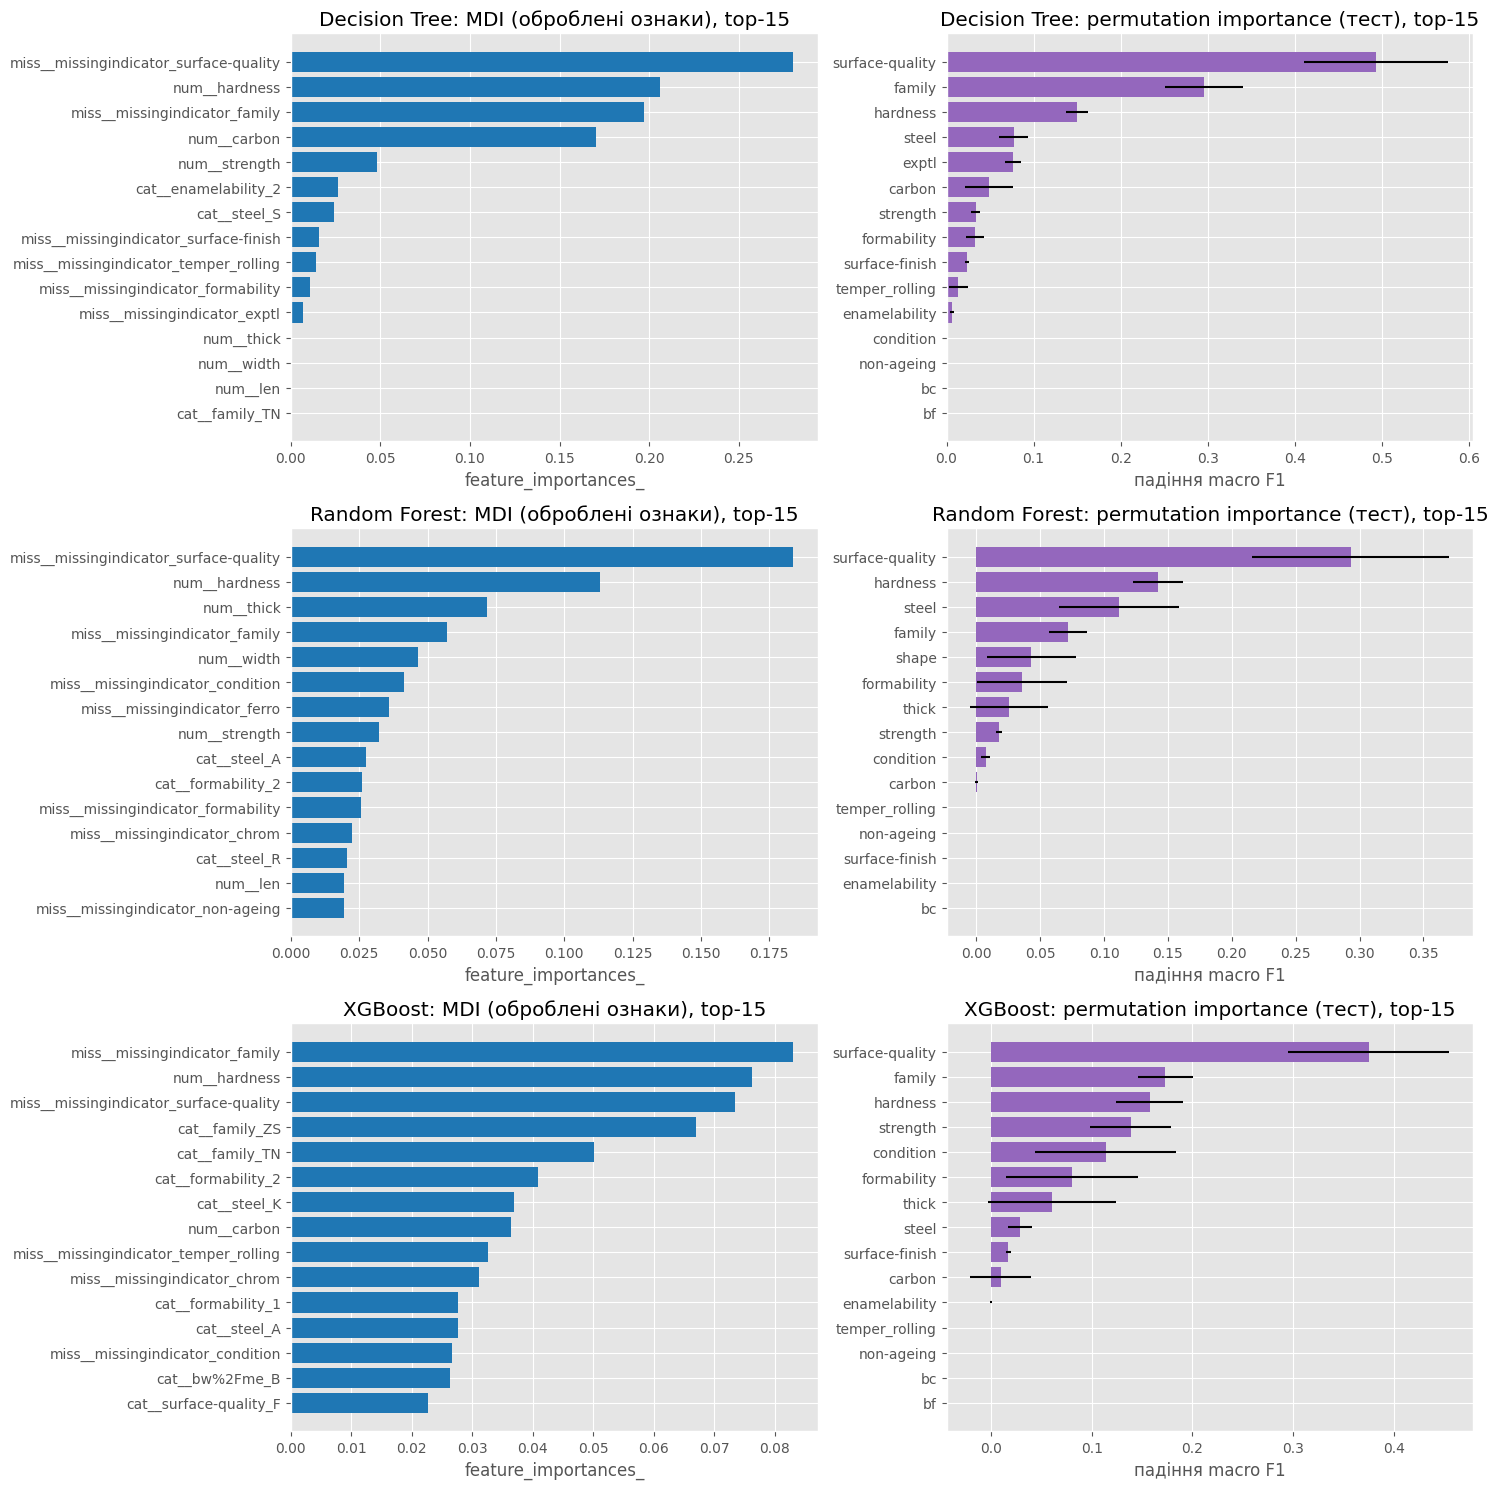

Decision Tree: індикаторів у top-15 MDI: 6; ранги: {'miss__missingindicator_surface-quality': 1, 'miss__missingindicator_family': 3, 'miss__missingindicator_surface-finish': 8, 'miss__missingindicator_temper_rolling': 9, 'miss__missingindicator_formability': 10, 'miss__missingindicator_exptl': 11}
Random Forest: індикаторів у top-15 MDI: 7; ранги: {'miss__missingindicator_surface-quality': 1, 'miss__missingindicator_family': 4, 'miss__missingindicator_condition': 6, 'miss__missingindicator_ferro': 7, 'miss__missingindicator_formability': 11, 'miss__missingindicator_chrom': 12, 'miss__missingindicator_non-ageing': 15}
XGBoost: індикаторів у top-15 MDI: 5; ранги: {'miss__missingindicator_family': 1, 'miss__missingindicator_surface-quality': 3, 'miss__missingindicator_temper_rolling': 9, 'miss__missingindicator_chrom': 10, 'miss__missingindicator_condition': 13}


In [15]:
from sklearn.inspection import permutation_importance

imp = {}
for name in MODELS:
    pipe = final_models[name]
    prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
    mdi = pd.Series(clf.feature_importances_, index=prep.get_feature_names_out())
    pi = permutation_importance(pipe, X_test, y_test, scoring='f1_macro',
                                n_repeats=N_PERM_REPEATS, random_state=SEED, n_jobs=1)
    perm = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std},
                        index=X_test.columns)
    imp[name] = {'mdi': mdi, 'perm': perm}

fig, axes = plt.subplots(len(MODELS), 2, figsize=(15, 5 * len(MODELS)))
for r, name in enumerate(MODELS):
    top = imp[name]['mdi'].nlargest(15)[::-1]
    axes[r, 0].barh(top.index, top.values, color='tab:blue')
    axes[r, 0].set_title(f'{MODEL_TITLES[name]}: MDI (оброблені ознаки), top-15')
    axes[r, 0].set_xlabel('feature_importances_')

    topp = imp[name]['perm'].nlargest(15, 'mean')[::-1]
    axes[r, 1].barh(topp.index, topp['mean'], xerr=topp['std'], color='tab:purple')
    axes[r, 1].set_title(f'{MODEL_TITLES[name]}: permutation importance (тест), top-15')
    axes[r, 1].set_xlabel('падіння macro F1')
plt.tight_layout()
plt.show()


for name in MODELS:
    top15 = imp[name]['mdi'].nlargest(15)
    ranks = {n: i + 1 for i, n in enumerate(top15.index) if 'missingindicator_' in n}
    print(f'{MODEL_TITLES[name]}: індикаторів у top-15 MDI: {len(ranks)}; ранги: {ranks or "—"}')

**Відповіді на запитання п. 3.7.**

**1) Чи потрапили індикатори пропусків до top-15 за MDI?** Так, у всіх моделей: у DT — 6 індикаторів (ранги 1, 3, 8, 9, 10, 11), у RF — 7 (1, 4, 6, 7, 11, 12, 15), у XGBoost — 5 (1, 3, 9, 10, 13); індикатори `surface-quality` і `family` входять до top-4 у всіх трьох моделей. Отже, сам факт пропуску несе інформацію про клас. Це узгоджується з п. 3.1: пропуски не є MCAR, а залежать від класу (саме в `surface-quality` і `family` найбільші χ², 495.6 і 463.7), і пояснює приріст якості у варіанті B. Permutation importance це підтверджує: ознака `surface-quality` є першою в усіх моделей (≈0.49 у DT, ≈0.29 у RF, ≈0.38 в XGBoost).

**2) Наскільки узгоджуються MDI та permutation importance?** Частково. Лідери збігаються: `surface-quality`, `family`, `hardness` стоять угорі обох рейтингів. Розбіжності такі. (а) MDI обчислюється на тренувальних даних для оброблених ознак, тому важливість категоріальної ознаки розпорошується між one-hot стовпцями (`steel_S`, `steel_A`, `steel_R`…), і `steel` у MDI виглядає слабкою, тоді як permutation importance вихідної ознаки `steel` помітна (≈0.08 для DT, ≈0.11 для RF). (б) **MDI зміщена на користь ознак із великою кількістю унікальних значень**: неперервні ознаки мають більше можливих порогів розбиття й частіше обираються, навіть якщо не узагальнюються. У RF `width` посідає 5-те місце за MDI (≈0.05), а permutation importance `width` близька до нуля (її немає серед top-15 перестановок), `thick` — 3-тє місце за MDI проти ≈0.025 за перестановкою. (в) Permutation importance обчислено на тесті з 180 об'єктів, тому вона має великі похибки (до ±0.08 для лідерів).

**3) Чому важливості однієї ознаки можуть суттєво відрізнятися між DT, RF і XGBoost?** Окреме дерево жадібно обирає кілька ознак: у DT чотири ознаки (індикатори `surface-quality` та `family`, `hardness`, `carbon`) дають приблизно 85 % сумарної MDI, а решта близькі до нуля. Random Forest усереднює багато дерев із випадковими підмножинами ознак, тому розподіляє важливість між корельованими ознаками (`thick`, `width`, категорії `steel`, різні індикатори). XGBoost будує дерева послідовно на залишках попередніх, тому виділяє ознаки, що виправляють помилки ансамблю, і має найплоскіший розподіл (максимум лише ≈0.08). Окрім того, багато індикаторів і ознак пропущені одночасно, тобто взаємозамінні, тож те, яка з них потрапить у розбиття, значною мірою випадкове; гіперпараметри (глибина 18, 25 та 7) також різні.

## 3.8 Аналіз розбіжностей між моделями
Об'єкт вважається об'єктом розбіжності, якщо прогнози трьох фінальних моделей не всі однакові. Потрібно знайти не менше трьох таких об'єктів у тесті.

In [16]:
from sklearn.model_selection import cross_val_predict

MIN_DISAGREE = 3     # потрібно не менше трьох об'єктів

P_test = np.vstack([test_pred[n] for n in MODELS])
dis_test_pos = np.where((P_test != P_test[0]).any(axis=0))[0]

rows, meta = [], []
for pos in dis_test_pos:
    idx = X_test.index[pos]
    rows.append({'Об\'єкт': f'#{idx}', 'Джерело': 'тест', 'Справжній клас': class_names[y_test[pos]],
                 **{MODEL_TITLES[n]: class_names[test_pred[n][pos]] for n in MODELS}})
    meta.append(('test', idx))

n_from_test = len(rows)
if n_from_test < MIN_DISAGREE:
    # Доповнюємо out-of-fold прогнозами (cross_val_predict)
    oof_pred = {n: cross_val_predict(build_pipeline(n, True, studies[n].best_params),
                                     X_train, y_train, cv=outer) for n in MODELS}
    P_oof = np.vstack([oof_pred[n] for n in MODELS])
    dis_oof_pos = np.where((P_oof != P_oof[0]).any(axis=0))[0]
    for pos in dis_oof_pos[:MIN_DISAGREE - n_from_test]:
        idx = X_train.index[pos]
        rows.append({'Об\'єкт': f'#{idx}', 'Джерело': 'train (out-of-fold)',
                     'Справжній клас': class_names[y_train[pos]],
                     **{MODEL_TITLES[n]: class_names[oof_pred[n][pos]] for n in MODELS}})
        meta.append(('train', idx))
    print(f'У тесті лише {n_from_test} об\'єкт(ів) розбіжності -- доповнено '
          f'{len(rows) - n_from_test} об\'єктами з train за out-of-fold прогнозами.')
if len(rows) < MIN_DISAGREE:
    print(f'УВАГА: знайдено лише {len(rows)} об\'єктів розбіжності (< {MIN_DISAGREE}).')

print('Таблиця 7. Об\'єкти розбіжності між прогнозами моделей')
display(pd.DataFrame(rows).set_index('Об\'єкт'))

У тесті лише 1 об'єкт(ів) розбіжності -- доповнено 2 об'єктами з train за out-of-fold прогнозами.
Таблиця 7. Об'єкти розбіжності між прогнозами моделей


,Джерело,Справжній клас,Decision Tree,Random Forest,XGBoost
Об'єкт,,,,,
#406,тест,1,1,1,3
#188,train (out-of-fold),1,5,3,3
#288,train (out-of-fold),1,1,1,3


У тестовій вибірці розбіжність знайдено лише для одного об'єкта (#406), тобто менше за потрібні три. Тому, як передбачає завдання, таблицю доповнено двома об'єктами з тренувальної вибірки (#188 і #288), для яких використано out-of-fold прогнози (`cross_val_predict`, 5-блочна стратифікована CV з найкращими гіперпараметрами), а не прогнози моделей на тих самих тренувальних даних. Слід зважати, що гіперпараметри підбиралися на всьому train, тож OOF-прогнози трохи оптимістичні. Усі три об'єкти належать до класу 1 (найменшого), і XGBoost помилився на кожному з них, віддавши перевагу домінантному класу 3; DT і RF правильно передбачили #406 та #288, а на #188 їхні прогнози різні й обидва хибні (5 і 3). Отже, розбіжності зосереджено на найрідкіснішому класі.

Для детального аналізу розбіжності обрано об'єкт #406 із тесту (справжній клас 1; DT і RF прогнозують 1, XGBoost — 3); оскільки він із тесту, фінальні моделі його під час навчання не бачили. Нижче виведено всі ознаки з початковими значеннями, позначено пропущені та значення, якими їх заповнено, і ймовірності `predict_proba`.

In [17]:
focus_src, focus_idx = meta[0]
x_row = (X_test if focus_src == 'test' else X_train).loc[[focus_idx]]
print(f'Аналізований об\'єкт: #{focus_idx} (джерело: {focus_src})')

# Усі ознаки з початковими значеннями; пропущені та значення імпутації
prep0 = final_models['DT'].named_steps['prep']      # імпутери однакові в усіх моделей
imputed_vals = dict(zip(prep0.named_transformers_['num'].feature_names_in_,
                        prep0.named_transformers_['num'].statistics_))
imputed_vals.update(dict(zip(
    prep0.named_transformers_['cat'].named_steps['impute'].feature_names_in_,
    prep0.named_transformers_['cat'].named_steps['impute'].statistics_)))

raw = x_row.iloc[0]
display(pd.DataFrame({
    'початкове значення': raw.values,
    'пропуск': raw.isna().values,
    'значення після імпутації': [imputed_vals[c] if pd.isna(raw[c]) else '—' for c in raw.index],
}, index=raw.index))

# Ймовірності predict_proba: близькість до межі між класами
proba_df = pd.DataFrame({MODEL_TITLES[n]: final_models[n].predict_proba(x_row)[0] for n in MODELS},
                        index=[f'P(клас {c})' for c in class_names]).T
proba_df['прогноз'] = [class_names[final_models[n].predict(x_row)[0]] for n in MODELS]
print('Ймовірності прогнозів:')
display(proba_df.round(3))

Аналізований об'єкт: #406 (джерело: test)


,початкове значення,пропуск,значення після імпутації
family,NaN,True,TN
steel,S,False,—
carbon,0,False,—
hardness,0,False,—
temper_rolling,NaN,True,T
condition,NaN,True,S
formability,NaN,True,2
strength,700,False,—
non-ageing,NaN,True,N
surface-finish,NaN,True,P


Ймовірності прогнозів:


,P(клас 1),P(клас 2),P(клас 3),P(клас 5),P(клас U),прогноз
Decision Tree,1.000,0.000,0.000,0.000,0.000,1
Random Forest,0.602,0.210,0.188,0.000,0.000,1
XGBoost,0.341,0.125,0.504,0.017,0.012,3


Із 31 ознаки в об'єкта #406 пропущено 22, і всі вони категоріальні (`family`, `temper_rolling`, `condition`, `formability`, `non-ageing`, `surface-finish`, `surface-quality`, `enamelability`, `bc`, `bf`, `bt`, `bw%2Fme`, `bl`, `chrom`, `phos`, `cbond`, `exptl`, `ferro`, `blue%2Fbright%2Fvarn%2Fclean`, `lustre`, `oil`, `packing`); відомі лише `steel = S`, `carbon = 0`, `hardness = 0`, `strength = 700`, `shape = COIL`, `thick = 1.0`, `width = 609.9`, `len = 0`, `bore = 0`. Імпутація заповнила пропуски модами тренувальної вибірки, де домінує клас 3 (76 %): `family = TN`, `condition = S`, `formability = 2`, `surface-quality = E`, `enamelability = 2`, `packing = 3` тощо. Це штучні значення, що описують типовий об'єкт, а не цей конкретний, — зокрема, пропуски є структурними, і правдоподібного значення для них немає; саме тому інформацію про відсутність значень зберігають індикатори.

Ймовірності прогнозів: DT — 1.000 для класу 1; RF — 0.602 (клас 1), 0.210 (клас 2), 0.188 (клас 3); XGBoost — 0.504 для класу 3 та 0.341 для класу 1. Тобто об'єкт лежить поблизу межі між класами 1 і 3: розрив між двома найімовірнішими класами в XGBoost становить лише ≈0.16, у RF — ≈0.39, і лише одне дерево впевнене у класі 1.

Топ-5 ознак за |SHAP| у прогнозований клас (об'єкт #406):


Прогноз                      Ознака (оброблена)  Значення  \
Модель        Ранг                                                             
Decision Tree 1          1                            cat__steel_S       1.0   
              2          1  miss__missingindicator_surface-quality       1.0   
              3          1                             num__carbon       0.0   
              4          1           miss__missingindicator_family       1.0   
              5          1                    cat__enamelability_2       1.0   
Random Forest 1          1                            cat__steel_S       1.0   
              2          1  miss__missingindicator_surface-quality       1.0   
              3          1                              num__thick       1.0   
              4          1      miss__missingindicator_formability       1.0   
              5          1        miss__missingindicator_condition       1.0   
XGBoost       1          3  miss__missingindicator_surface-quality       1.0   
              2          3                             num__carbon       0.0   
              3          3                           num__hardness       0.0   
              4          3        miss__missingindicator_condition       1.0   
              5          3                           num__strength     700.0   

                        SHAP  
Модель        Ранг            
Decision Tree 1     0.449999  
              2     0.298155  
              3     0.132111  
              4     0.095230  
              5     0.018348  
Random Forest 1     0.095789  
              2     0.084539  
              3     0.044680  
              4     0.035479  
              5     0.034673  
XGBoost       1    -0.699917  
              2    -0.227540  
              3     0.104979  
              4    -0.100109  
              5     0.092855

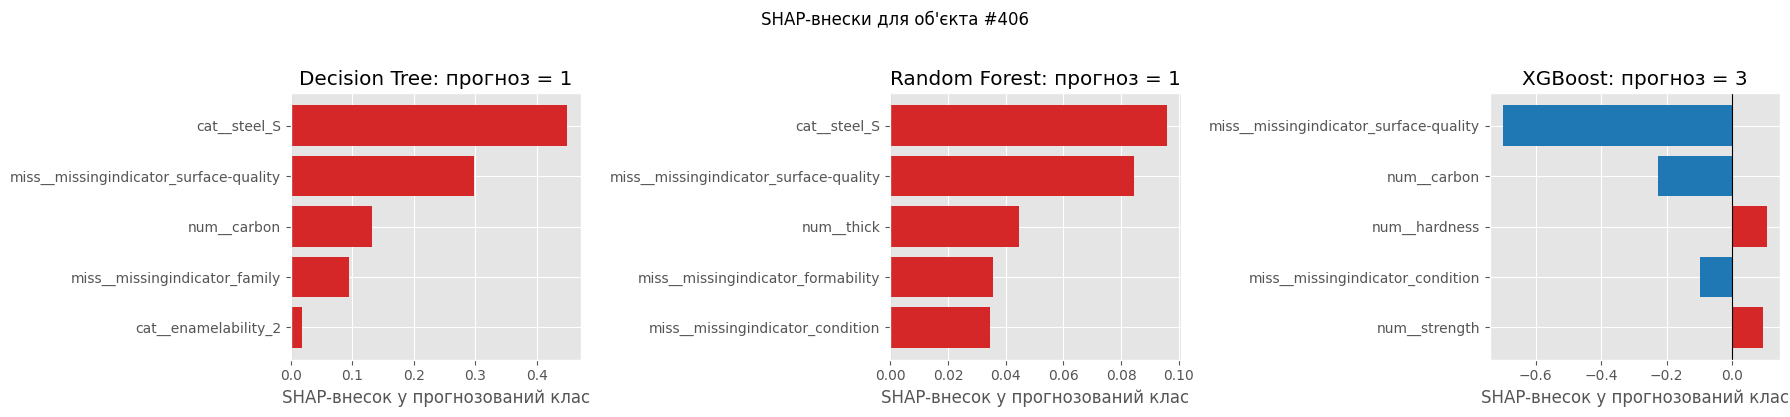

In [18]:
def shap_for_row(pipe, x_df):
    prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
    xp = pd.DataFrame(prep.transform(x_df), columns=prep.get_feature_names_out())
    try:
        explainer = shap.TreeExplainer(clf)
        sv = explainer.shap_values(xp.to_numpy(), check_additivity=False)
        sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)   # (1, F, K)
        return xp, sv[0]
    except Exception as exc:       # запасний варіант для несумісних версій shap/xgboost
        if not isinstance(clf, XGBClassifier):
            raise
        print(f'shap.TreeExplainer для XGBoost не спрацював ({type(exc).__name__}); '
              'використано pred_contribs (ті самі TreeSHAP-значення).')
        dm = xgboost.DMatrix(xp.to_numpy())
        contrib = clf.get_booster().predict(dm, pred_contribs=True)          # (1, K, F+1)
        return xp, np.transpose(contrib[0][:, :-1])


shap_rows, shap_store = [], {}
for name in MODELS:
    pipe = final_models[name]
    xp, sv = shap_for_row(pipe, x_row)
    pc = int(pipe.predict(x_row)[0])    # прогнозований клас
    order = np.argsort(-np.abs(sv[:, pc]))[:5]
    shap_store[name] = (xp, sv, pc, order)
    for rank, j in enumerate(order, start=1):
        shap_rows.append({'Модель': MODEL_TITLES[name], 'Прогноз': class_names[pc], 'Ранг': rank,
                          'Ознака (оброблена)': xp.columns[j],
                          'Значення': xp.iloc[0, j], 'SHAP': sv[j, pc]})
print(f'Топ-5 ознак за |SHAP| у прогнозований клас (об\'єкт #{focus_idx}):')
display(pd.DataFrame(shap_rows).set_index(['Модель', 'Ранг']))

# Графік 6: SHAP-внески для проаналізованого об'єкта
fig, axes = plt.subplots(1, len(MODELS), figsize=(6 * len(MODELS), 4))
for ax, name in zip(axes, MODELS):
    xp, sv, pc, order = shap_store[name]
    vals = sv[order, pc][::-1]
    labels = [xp.columns[j] for j in order][::-1]
    ax.barh(labels, vals, color=['tab:red' if v > 0 else 'tab:blue' for v in vals])
    ax.axvline(0, color='k', lw=0.8)
    ax.set_title(f'{MODEL_TITLES[name]}: прогноз = {class_names[pc]}')
    ax.set_xlabel('SHAP-внесок у прогнозований клас')
fig.suptitle(f'SHAP-внески для об\'єкта #{focus_idx}', y=1.03)
plt.tight_layout()
plt.show()

Значення SHAP обчислено через `shap.TreeExplainer` для прогнозованого кожною моделлю класу (DT і RF — клас 1, XGBoost — клас 3). Топ-5 внесків: **DT** — `steel = S` (+0.450), індикатор пропуску `surface-quality` (+0.298), `carbon = 0` (+0.132), індикатор `family` (+0.095), `enamelability_2` (+0.018; це *імпутоване* значення, бо в об'єкта `enamelability` пропущена); **RF** — `steel = S` (+0.096), індикатор `surface-quality` (+0.085), `thick` (+0.045), індикатори `formability` (+0.035) та `condition` (+0.035); **XGBoost** — індикатор `surface-quality` (−0.700), `carbon` (−0.228), `hardness` (+0.105), індикатор `condition` (−0.100), `strength` (+0.093). Для DT і RF значення SHAP виражені в одиницях ймовірності, а для XGBoost — в логітах (маржа), тому їхні величини безпосередньо порівнювати не можна.

**Порівняння ознак між моделями та причини розбіжності.**
- *Спільне й відмінне.* Індикатор `surface-quality` є в топ-5 усіх трьох моделей; `steel = S` — у DT і RF, `carbon` — у DT і XGBoost, індикатор `condition` — у RF і XGBoost. Тобто моделі сходяться в тому, що пропуск `surface-quality` — головний сигнал, але використовують його в тому самому напрямі по-різному: DT і RF — як свідчення *на користь* класу 1 (+0.298; +0.085), XGBoost — як свідчення *проти* класу 3 (−0.700). Решта ознак XGBoost (`hardness`, `strength`) підтримали клас 3, і, найімовірніше, через базове значення (клас 3 становить 76 % вибірки) та повільне навчання (`learning_rate ≈ 0.016`, імовірності залишаються м'якими) XGBoost залишився на боці класу 3, хоча сума внесків його топ-5 від'ємна (≈−0.83).
- *Роль імпутованих значень та індикаторів.* У топ-5 DT є два індикатори та одне імпутоване one-hot значення (`enamelability_2`), у RF — три індикатори, в XGBoost — два індикатори. Тобто від 2 до 3 із 5 найвпливовіших ознак пов'язані саме з пропусками й імпутацією, і моделі по-різному обирають серед численних взаємозамінних індикаторів (`family`, `formability`, `condition`).
- *Жорсткі пороги одного дерева проти усереднення в ансамблях.* DT проводить об'єкт гілками з порогами на кількох ознаках (`steel`, індикатори, `carbon`) до чистого листка класу 1 (P = 1.000), тоді як RF усереднює сотні дерев і розмиває цю впевненість до 0.602, залишаючи по ≈0.2 класам 2 і 3.
- *Близькість до межі між класами.* Різниця P(3) − P(1) в XGBoost становить лише ≈0.16, тому невелика зміна ваги кількох ознак перекидає прогноз з класу 1 на клас 3; те саме видно за ймовірностями RF (0.602 проти 0.210 та 0.188).

## Висновок

Для Random Forest отримано найвищу macro F1 — 0.9271 ± 0.0959 у базовому варіанті B та 0.9406 ± 0.0859 у вкладеній крос-валідації, проте стандартне відхилення (≈0.09) значно перевищує різниці між моделями. Скоригований тест Надо–Бенжіо не підтверджує переваги RF над XGBoost ($\bar d$ = 0.0091, p = 0.4058), тому ці дві моделі статистично нерозрізнювані. Індикатори пропусків підвищили macro F1 в усіх моделей (DT на 0.0656, RF на 0.0537, XGBoost на 0.0839) і accuracy з ≈0.95 до ≈0.99, причому для DT і RF приріст значущий (p = 0.0004 і 0.0002), а для XGBoost — ні (p = 0.1217) через велику дисперсію різниць по блоках. Це узгоджується з аналізом механізму пропусків (у 21 із 23 ознак пропуск залежить від класу, тобто MCAR відхилено) і з важливістю ознак: індикатори `surface-quality` та `family` входять до top-4 за MDI в усіх трьох моделей, а permutation importance ознаки `surface-quality` найвища в усіх. Значення best_value завищує якість порівняно з вкладеною CV на 0.1009 для DT, 0.0337 для XGBoost і лише 0.0119 для RF, тобто оптимістичне зміщення найбільше в нестабільного окремого дерева. Приріст після оптимізації мав лише Random Forest (0.9406 проти 0.9271 у базовій моделі), тоді як для DT (0.8470 проти 0.9142) і XGBoost (0.8950 проти 0.9179) вкладені оцінки не зросли, але ці порівняння виконано на різних розбиттях, а різниці менші за розкид оцінок. Найскладнішими виявилися клас U (F1 = 0.75, плутається з класом 3) і найменший клас 1 (8 об'єктів), на якому моделі нестабільні. Усі три знайдені об'єкти розбіжності (#406, #188, #288) належать до класу 1, а XGBoost помилився на кожному з них, віддавши перевагу домінантному класу 3. Для об'єкта #406 із 22 пропущеними ознаками з 31 усі моделі виділили індикатор `surface-quality`, але XGBoost із ймовірностями 0.504 для класу 3 та 0.341 для класу 1 опинився по інший бік межі, тоді як дерево дало 1.000 завдяки жорсткому порогу, а ліс усереднив до 0.602. Різниця на тесті між XGBoost (macro F1 0.8797) і DT та RF (0.9471) зумовлена саме цим одним об'єктом, тому тестові оцінки при 2 об'єктах класу 1 і 8 об'єктах класу U слід вважати грубими. Для практичного використання доцільно обрати Random Forest, бо вона має найвищі вкладену оцінку (0.9406) та тестову macro F1 (0.9471) і найменше оптимістичне зміщення (0.0119), а її поведінку можна пояснити через MDI, permutation importance та SHAP. Водночас ліс із 400 дерев значно дорожчий за одне дерево за часом навчання й обсягом пам'яті, тому за жорстких обмежень на ресурси варто розглянути й Decision Tree, хоча його вкладена оцінка (0.8470) нижча.

## Відповіді на контрольні питання

**1. Чим випадковий ліс відрізняється від окремого дерева рішень з погляду розкладу похибки на зміщення та дисперсію? Яку роль відіграє декореляція дерев?**
Окреме глибоке дерево має низьке зміщення, але високу дисперсію: невелика зміна навчальної вибірки дає зовсім інше дерево. Random Forest усереднює $B$ дерев, навчених на bootstrap-вибірках і з випадковою підмножиною ознак у кожному вузлі; дисперсія середнього дорівнює $\rho\sigma^2+\frac{1-\rho}{B}\sigma^2$, тож збільшення $B$ зменшує другий доданок, а зміщення майже не змінюється. Декореляція дерев (менше $\rho$) є ключовою: без випадкового вибору ознак дерева були б схожими, і усереднення давало б малий виграш. У нашому експерименті це проявляється в стабільності: оптимістичне зміщення `best_value` для DT (0.1009) значно більше, ніж для RF (0.0119).

**2. У чому принципова різниця між бустингом і беггінгом? Який із методів схильніший до перенавчання з ростом кількості дерев і чому?**
Беггінг тренує дерева незалежно на bootstrap-вибірках і усереднює їх, зменшуючи переважно дисперсію. Бустинг будує дерева послідовно: кожне наступне апроксимує антиградієнт функції втрат поточного ансамблю (залишки), зменшуючи переважно зміщення, а внесок дерева стискається множником `learning_rate`. Схильнішим до перенавчання з ростом кількості дерев є бустинг: похибка лісу при збільшенні $B$ виходить на плато (закон великих чисел), тоді як бустинг продовжує підлаштовуватися під навчальні дані й потребує регуляризації (мала швидкість навчання, `subsample`, обмеження глибини, `min_child_weight`, ранню зупинку).

**3. Чому macro F1 і balanced accuracy інформативніші за accuracy в умовах дисбалансу? У чому різниця між macro- та weighted-усередненням F1?**
За дисбалансу accuracy визначається мажоритарним класом: у нас клас 3 становить 76.2 %, тож тривіальний класифікатор, що завжди прогнозує клас 3, мав би accuracy ≈0.76 при нульовій якості для решти класів. Macro F1 — середнє F1 за класами з однаковими вагами, а balanced accuracy — середній recall за класами, тому помилки на рідкісних класах (1, U) впливають так само, як на мажоритарному. Weighted-усереднення зважує F1 за кількістю об'єктів класу й тому майже повторює мажоритарний клас: для RF у `classification_report` macro F1 = 0.947, а weighted F1 = 0.978.

**4. Опишіть механізми MCAR, MAR і MNAR. За якого механізму індикатори пропусків найкорисніші? Чи можна за даними однозначно відрізнити MAR від MNAR?**
MCAR: імовірність пропуску не залежить ні від спостережуваних, ні від пропущених значень. MAR: залежить лише від спостережуваних даних (наприклад, від класу чи інших ознак). MNAR: залежить від самого пропущеного значення або від неспостережуваних чинників. Індикатори найкорисніші, коли пропуск інформативний, тобто за MAR чи MNAR, особливо якщо пов'язаний із цільовою змінною (як у нашому датасеті); за MCAR вони корисної інформації не несуть. За самими даними однозначно відрізнити MAR від MNAR не можна: MNAR означає залежність від значень, яких ми не бачимо, а перевірити можна лише залежність від спостережуваних величин (як χ²-тест із класом); потрібні знання про предметну область або аналіз чутливості.

**5. У яких місцях пайплайну може виникнути витік даних під час імпутації та оптимізації гіперпараметрів і як цьому запобігти?**
Під час імпутації витік виникає, якщо `fit_transform` імпутера (медіани, моди) виконати на всьому наборі до поділу чи крос-валідації: статистики валідаційних блоків потрапляють у навчання. Під час оптимізації — якщо в Optuna передати заздалегідь оброблені `X_train_proc` (імпутер уже бачив валідаційні блоки внутрішньої CV) або використати тестову вибірку в цільовій функції чи для вибору моделі. Запобігання: уся обробка всередині `Pipeline`/`ColumnTransformer`, що навчається лише на тренувальній частині кожного блоку; у `tune()` у `cross_val_score` передається весь пайплайн; якість оцінюється вкладеною CV; тест використовується один раз. Описовий аналіз (частки пропусків, χ²-тест із класом) виконано на всіх даних, але він не впливає на навчання: видалення порожніх і константних ознак не залежить від `y`, а рішення щодо класів лише описове.

**6. Чому `best_value` оптимізації є оптимістично зміщеною оцінкою? Як працює вкладена крос-валідація і яку модель ми насправді оцінюємо в її зовнішньому циклі?**
`best_value` — це максимум із 30 зашумлених оцінок якості на тих самих блоках внутрішньої CV; математичне сподівання максимуму не менше за максимум сподівань, тому оцінка завищена. У вкладеній CV зовнішній цикл ділить дані на блоки; на тренувальній частині кожного блоку внутрішній цикл підбирає гіперпараметри, а якість обчислюється на відкладеному зовнішньому блоці, що в підборі не брав участі. У зовнішньому циклі оцінюється не одна конкретна модель, а вся процедура «підбір гіперпараметрів + навчання», яка на різних блоках може обирати різні конфігурації.

**7. Чому звичайний парний t-тест не підходить для порівняння результатів крос-валідації? Яку поправку вносить тест Надо–Бенжіо?**
Тренувальні вибірки різних блоків перекриваються (у 5-блочній CV два блоки мають спільними близько 75 % тренувальних даних), а повторення використовують ті самі дані, тож оцінки на блоках залежні. Дисперсія середнього різниці в звичайному t-тесті ($\hat\sigma_d^2/kr$) занижується, t завищується й хибнопозитивних висновків стає забагато. Поправка Надо–Бенжіо замінює множник $1/kr$ на $\left(1/kr+n_{test}/n_{train}\right)$, тобто додає складову, що враховує кореляцію блоків; ступені свободи — $kr-1$. У нашій роботі $kr=15$, $n_{test}/n_{train}\approx0.25$: множник зростає з ≈0.067 до ≈0.317, а стандартна похибка — приблизно в 2.2 раза.

**8. Чим MDI-важливість відрізняється від permutation importance? Як корельовані ознаки впливають на кожну з них?**
MDI (`feature_importances_`) — сумарне зменшення неоднорідності від розбиттів за ознакою; обчислюється на навчальних даних, залежить від структури моделі, зміщена на користь ознак з багатьма унікальними значеннями й може бути високою для ознак, що не узагальнюються. Permutation importance — зниження метрики (macro F1) на відкладених даних при випадковому перемішуванні ознаки; вона модельно-незалежна й застосована до всього пайплайну, тобто до вихідних ознак. Корельовані ознаки: у MDI важливість довільно розподіляється між ними залежно від того, яку обере дерево; у permutation importance кожна з них недооцінюється, бо корельований двійник компенсує перемішування, до того ж виникають нереалістичні комбінації значень. У нас значення `surface-quality` і її індикатор перемішуються разом, тоді як у MDI вони окремі ознаки.

**9. Що таке SHAP-значення і яку властивість (адитивність) вони задовольняють? Чим локальне пояснення відрізняється від глобальної важливості?**
Значення Шеплі $\varphi_i$ — внесок ознаки $i$ у відхилення прогнозу для конкретного об'єкта від середнього прогнозу, обчислений усередненням маргінального внеску ознаки за всіма підмножинами ознак (теорія кооперативних ігор); `TreeExplainer` обчислює їх точно й ефективно для дерев. Адитивність (локальна точність): $f(x)=\varphi_0+\sum_i\varphi_i$; також виконуються симетрія, нульовий внесок для незадіяної ознаки та консистентність. Локальне пояснення стосується одного прогнозу (як для об'єкта #406), а глобальна важливість характеризує модель загалом (MDI, permutation importance або середнє $|\varphi_i|$ за багатьма об'єктами).

**10. Як алгоритм XGBoost обробляє пропущені значення нативно (sparsity-aware split finding)?**
Під час пошуку розбиття за ознакою алгоритм розглядає лише непропущені значення, а об'єкти з пропусками по черзі відправляє в ліву й у праву гілку та обирає напрям, що дає більший приріст. Цей напрям за замовчуванням зберігається у вузлі й застосовується до пропусків під час прогнозування. Складність лінійна за кількістю непропущених елементів. У цій роботі пропуски імпутовано явно, щоб моделі отримували однакові входи; нативну обробку досліджує додаткове завдання.

**11. Які переваги має Optuna (TPE-семплер, прунінг) порівняно з `GridSearchCV` та `RandomizedSearchCV`?**
TPE (Tree-structured Parzen Estimator) моделює щільності хороших і поганих спроб і вибирає наступні точки там, де їхнє відношення найбільше, тобто використовує історію й знаходить добрі конфігурації за меншої кількості спроб. `GridSearchCV` перебирає сітку, що експоненційно зростає з кількістю параметрів і марнує спроби на неважливі параметри (у нас 1–2 параметри визначають більшість варіації якості); `RandomizedSearchCV` семплює випадково, не використовує попередні результати, хоча й краще покриває важливі виміри. Optuna підтримує логарифмічні, цілі, категоріальні та умовні простори; прунінг (наприклад, `MedianPruner`) достроково припиняє безперспективні спроби за проміжними результатами й економить обчислення.